# Imports

In [1]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd
from tqdm import tqdm

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, DESIGN_WAVELENGTH, WIDTH, device_paths, export_device

# Design device

One arm has a delay bump, the other arm is straight but tapers to different widths with cosine tapers.

D:\DATA\ETL_PIC\simulation\rsoft_lib\geometry.py:343: UserWarning: The middle straight is only 367.9 um long: the two S-bends already take 3632.1 um of the 4000 um z-length (theta = 40.4 deg, offset 668.8 um). A longer z_length or a smaller R leaves more room.
  warnings.warn(f"The middle straight is only {L_mid:.1f} um long: the two S-bends already take {4 * R * np.sin(theta):.1f} um "


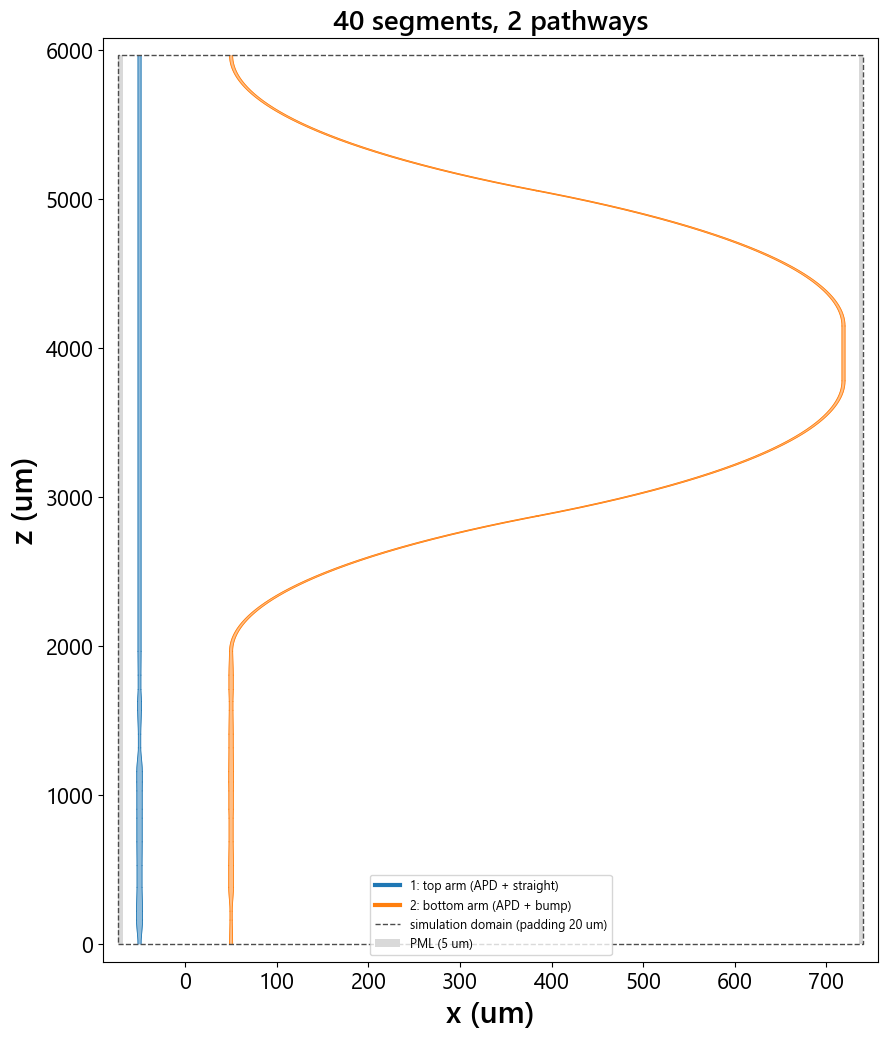

P-10b_APDMZI: 8 sections, APD 1964.6 μm, bump ΔL 320 μm, arms end at z = 5964.6280 (top) and 5964.6280 μm (bottom)
   bottom - top path length 320.000000 μm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-10_APDMZI\P-10b_APDMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-10_APDMZI\P-10b_APDMZI.gds; 59646 propagation steps per wavelength


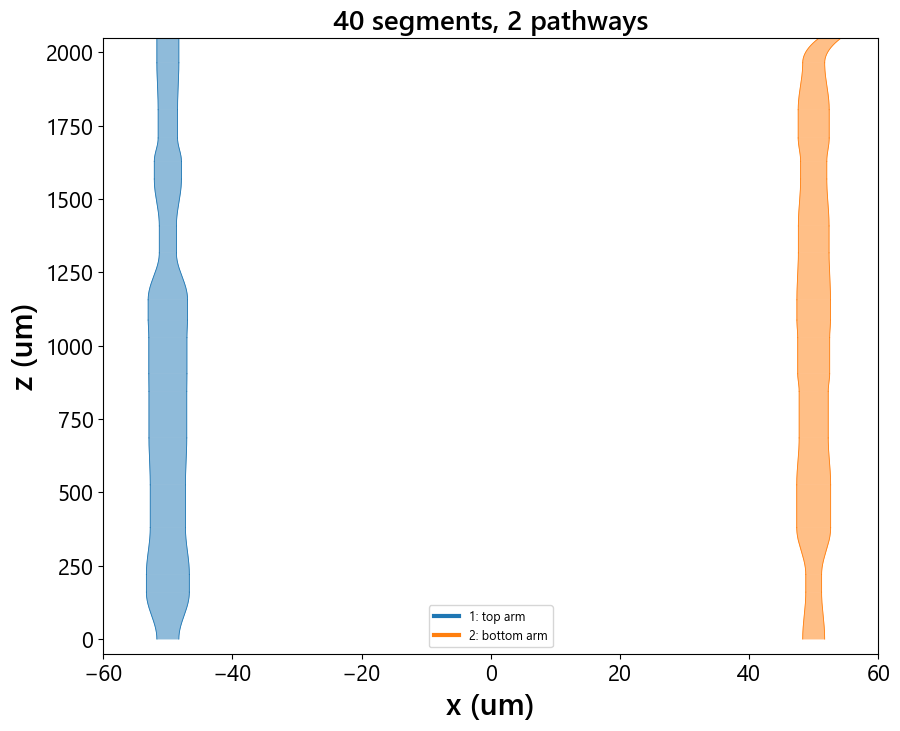

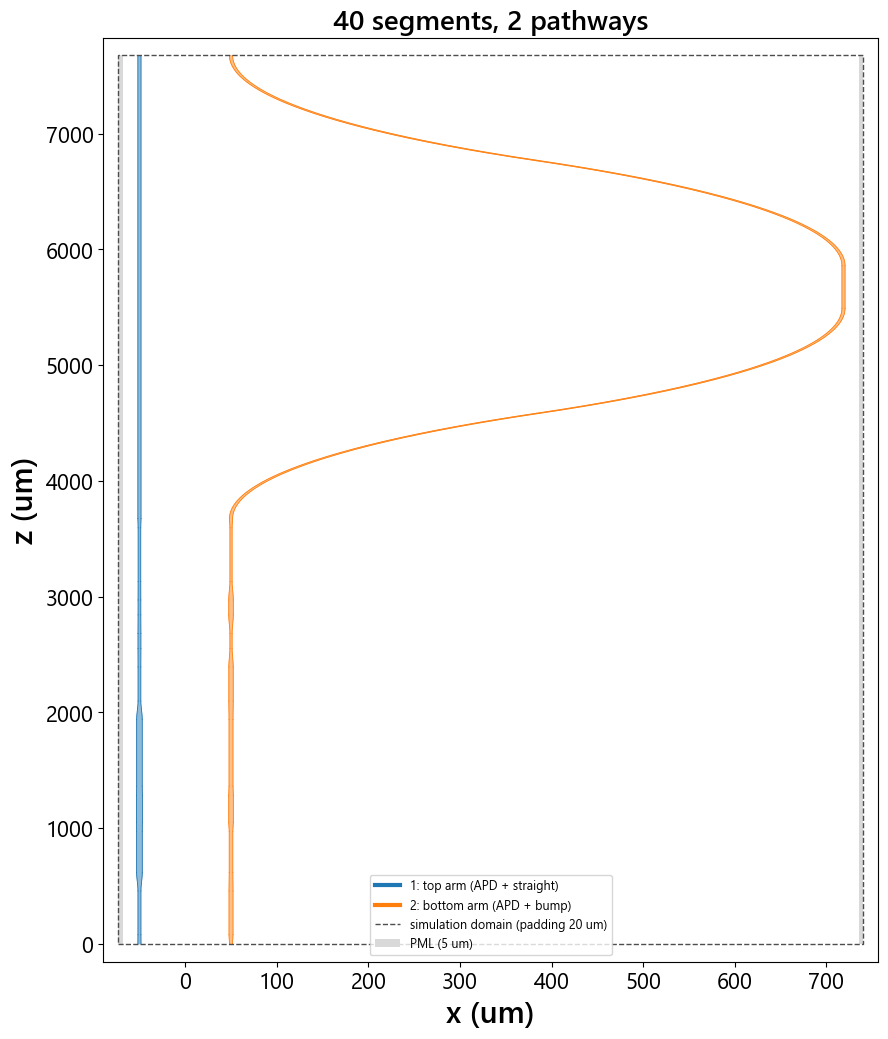

P-10c_APDMZI: 8 sections, APD 3675.3 μm, bump ΔL 320 μm, arms end at z = 7675.3090 (top) and 7675.3090 μm (bottom)
   bottom - top path length 320.000000 μm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-10_APDMZI\P-10c_APDMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-10_APDMZI\P-10c_APDMZI.gds; 76753 propagation steps per wavelength


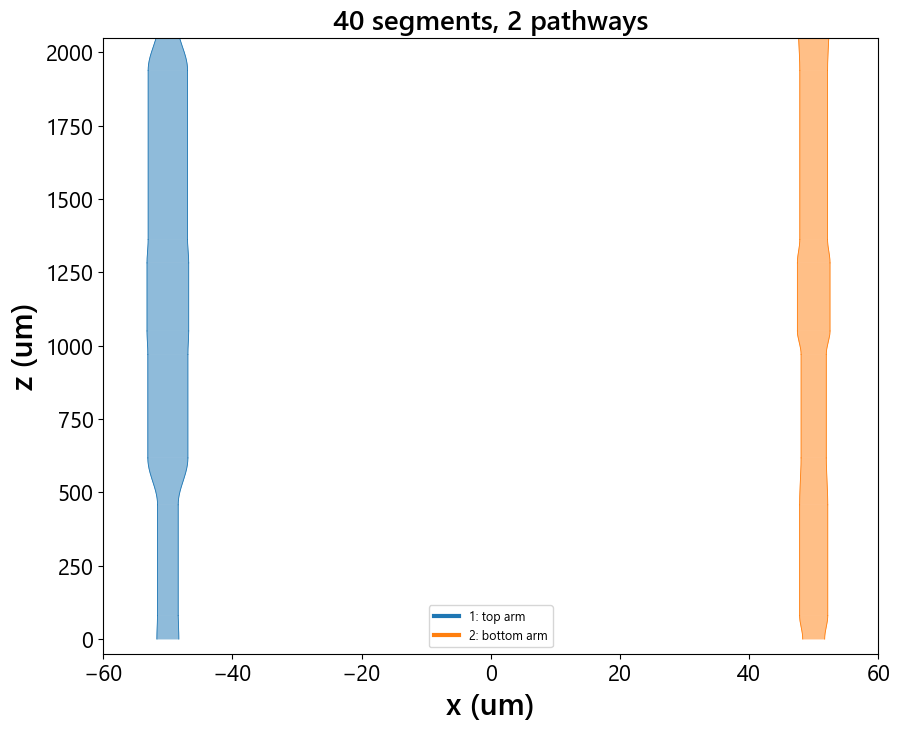

In [6]:
# Set up directories
device_name = 'P-10_APDMZI'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"

# Set up parameters: each design's two tables and its path offset (um, + = extra path in the top arm, - = in the bottom arm)
designs = {
    "P-10b_APDMZI": dict(sections=f"{device_dir}b_design4_latticeblind_v3.csv",
                         tapers=f"{device_dir}b_design4_latticeblind_v3_tapers.csv", path_offset=0.0),
    "P-10c_APDMZI": dict(sections=f"{device_dir}c_design2_standard_v3.csv",
                         tapers=f"{device_dir}c_design2_standard_v3_tapers.csv", path_offset=0.0),
}
arm_pitch = 100.0               # centre-to-centre distance of the two arms (um)

# The delay bump of P-05b, after the APD on the right arm: z length 4000 um, delta L 320 um, R 1400 um (no bend offsets, as in P-05b)
bump_z, bump_dL, bump_R = 4000.0, 320.0, 1400.0
bump = rlib.delay_arm_parameters(bump_z, bump_dL, bump_R, end_straight=0)
bump_angle = np.degrees(bump["theta"])
bump_pieces = [("arc", bump_R, bump_angle), ("arc", bump_R, -bump_angle), ("line", bump["L_mid"]),
               ("arc", bump_R, -bump_angle), ("arc", bump_R, bump_angle)]                # S-bend out (+x), straight, S-bend back

circuits = {}
for design_name, d in designs.items():
    # Read APD parameters
    apd = rlib.read_apd_tables(d["sections"], d["tapers"])
    dL = d["path_offset"]

    # Construct circuit: top arm on the left (-x) then a straight as long in z as the bump, bottom arm on the right (+x) then the bump
    paths = device_paths(device_dir, design_name)
    c = rlib.Circuit(width=WIDTH, orientation="extended")
    top = c.add_route(-arm_pitch / 2, 0.0, 0.0, rlib.apd_pieces(apd, "top", path_offset=max(dL, 0.0)) + [("line", bump_z)],
                      width=apd["guide_width"])
    c.add_pathway(top["segments"], launch=True)
    bottom = c.add_route(arm_pitch / 2, 0.0, 0.0, rlib.apd_pieces(apd, "bottom", path_offset=max(-dL, 0.0)) + bump_pieces,
                         width=apd["guide_width"])
    c.add_pathway(bottom["segments"], launch=True)

    # Export and visualize circuit
    export_device(c, paths)
    circuits[design_name] = c
    c.plot(labels=["top arm (APD + straight)", "bottom arm (APD + bump)"], figsize=(10, 12))
    print(f"{design_name}: {len(apd['sections'])} sections, APD {apd['length']:.1f} μm, bump ΔL {bump_dL:g} μm, arms end at z = "
          f"{top['z_end']:.4f} (top) and {bottom['z_end']:.4f} μm (bottom)")
    print(f"   bottom - top path length {bottom['path_length'] - top['path_length']:.6f} μm")
    print(f"Wrote {paths['ind']} and {paths['gds']}; {max(top['z_end'], bottom['z_end']) / SIM['Step_z']:.0f} propagation steps per wavelength")

    c.plot(labels=["top arm", "bottom arm"], xlim=(-60, 60), ylim=(-50, 2050), domain=False, figsize=(10, 8))

# Estimate interference pattern

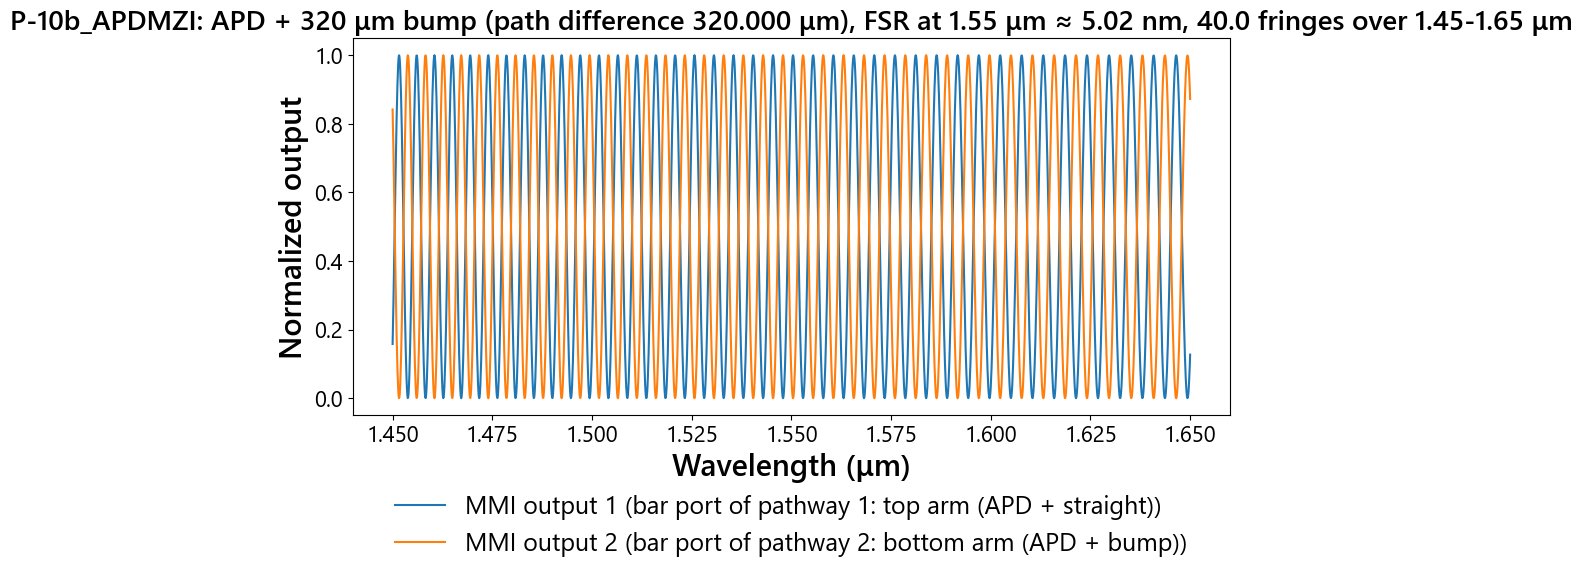

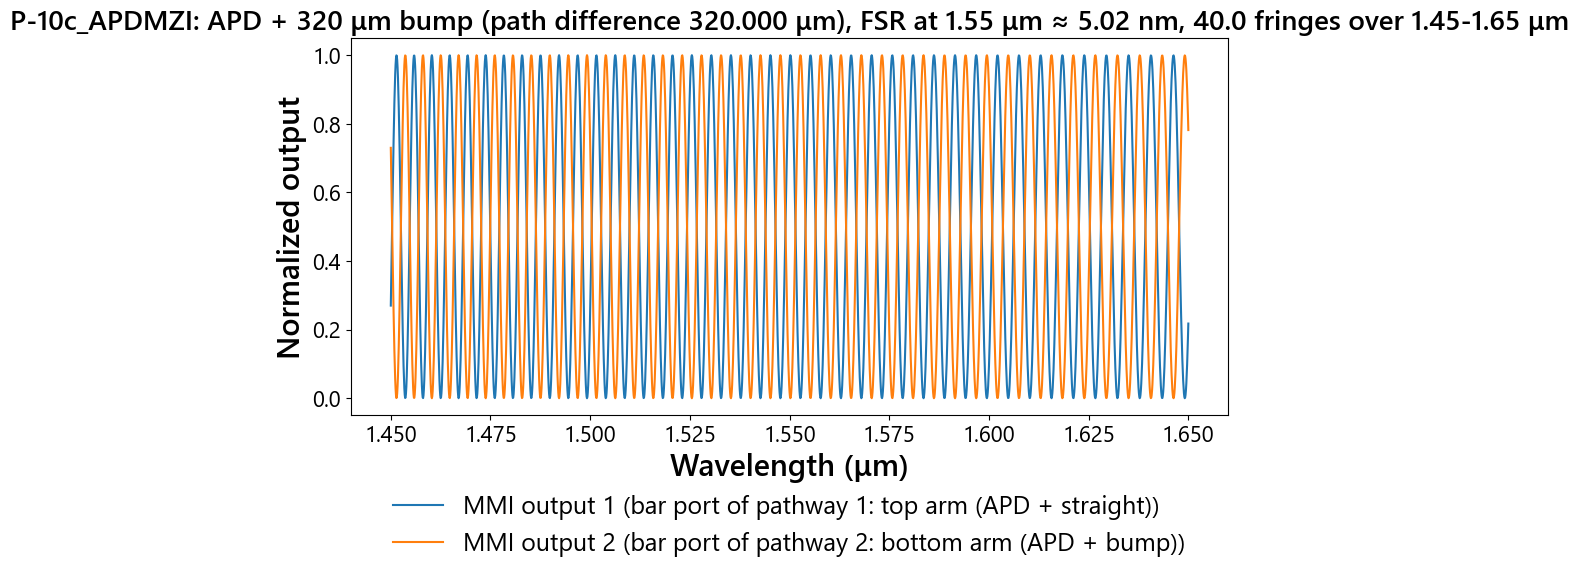

In [8]:
# %% Interference spectrum of each circuit: Y-splitter, the two pathways, 2x2 MMI
wl = np.linspace(1.45, 1.65, 2001)
tm = rlib.transfer
pathway_labels = ["top arm (APD + straight)", "bottom arm (APD + bump)"]

for design_name, c in circuits.items():
    est = rlib.estimate_pathways(c, wl)
    arm_a = tm.pathway(est, 1)                          # pathway 1: top arm (APD + straight)
    arm_b = tm.pathway(est, 2)                          # pathway 2: bottom arm (APD + bump)
    T = tm.mzi_response(wl, arm_a, arm_b, splitter="y", combiner="mmi")
    P = tm.power(T)                                     # (wavelengths, 2 outputs)
    diff = est.difference(2, 1)                         # bottom arm - top arm
    dphi = diff["phase"]
    n_fringes = abs(dphi[0] - dphi[-1]) / (2 * np.pi)
    fsr = tm.fsr(wl, dphi)

    plt.figure(figsize=(10, 6))
    plt.plot(wl, P[:, 0], label=f"MMI output 1 (bar port of pathway 1: {pathway_labels[0]})")
    plt.plot(wl, P[:, 1], label=f"MMI output 2 (bar port of pathway 2: {pathway_labels[1]})")
    plt.xlabel('Wavelength (μm)')
    plt.ylabel('Normalized output')
    plt.title(f"{design_name}: APD + {bump_dL:g} μm bump (path difference {diff['length']:.3f} μm), "
              f"FSR at 1.55 μm ≈ {np.interp(1.55, wl, fsr) * 1e3:.2f} nm, {n_fringes:.1f} fringes over {wl[0]:g}-{wl[-1]:g} μm")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)
    plt.tight_layout()
    plt.show()

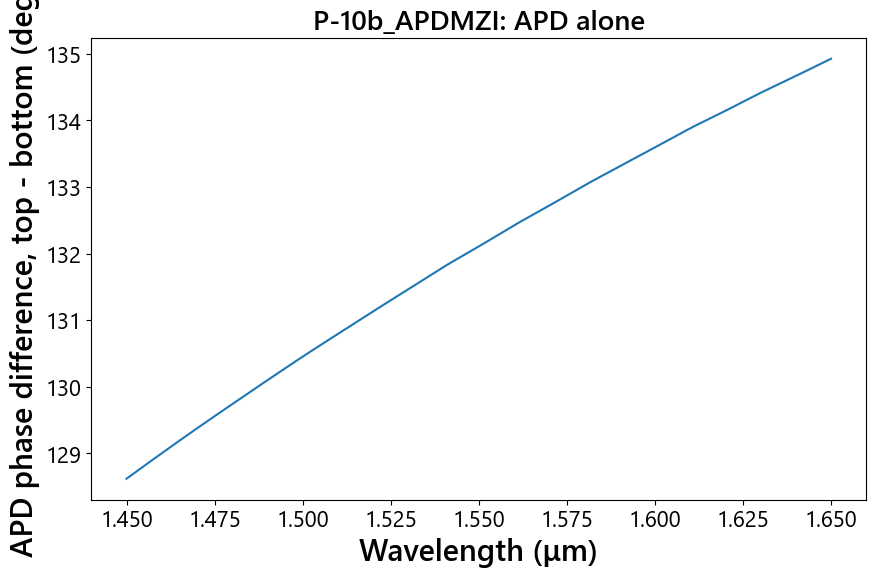

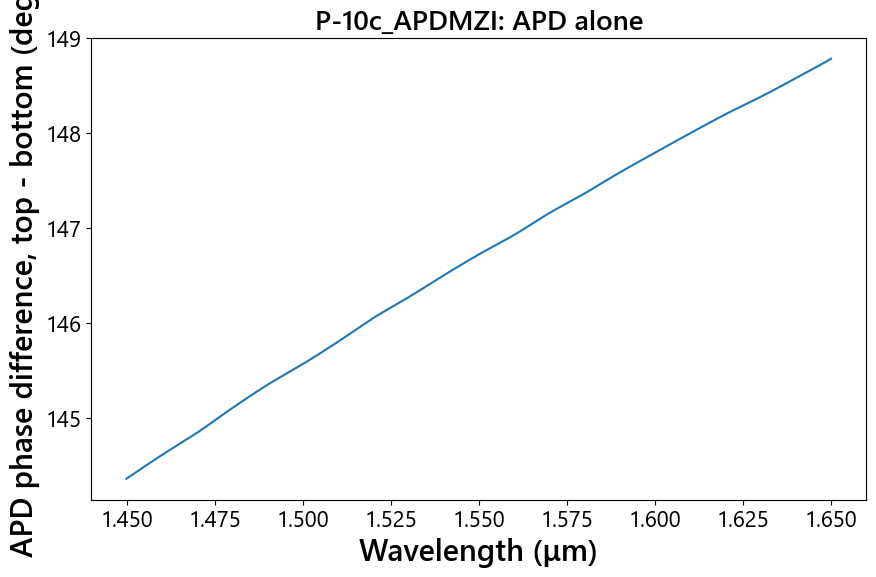

In [15]:
for design_name, c in circuits.items():
    d = designs[design_name]
    apd = rlib.read_apd_tables(d["sections"], d["tapers"])
    dL = d["path_offset"]
    est = rlib.estimate_pathways(c, wl)

    n_top = len(rlib.apd_pieces(apd, "top", path_offset=max(dL, 0.0)))       # the APD part of pathway 1
    n_bot = len(rlib.apd_pieces(apd, "bottom", path_offset=max(-dL, 0.0)))   # the APD part of pathway 2
    dphi_apd = (sum(r["phase"] for r in est[1].segments[:n_top])
                - sum(r["phase"] for r in est[2].segments[:n_bot]))          # top - bottom, rad

    plt.figure(figsize=(10, 6))
    plt.plot(wl, np.degrees(dphi_apd))
    plt.xlabel('Wavelength (μm)')
    plt.ylabel('APD phase difference, top - bottom (deg)')
    plt.title(f"{design_name}: APD alone")
    plt.show()

P-10c_APDMZI: after trim, worst 0.0143 deg (rms 0.0077); lattice-blind residual, worst 0.0133 deg (rms 0.0063)


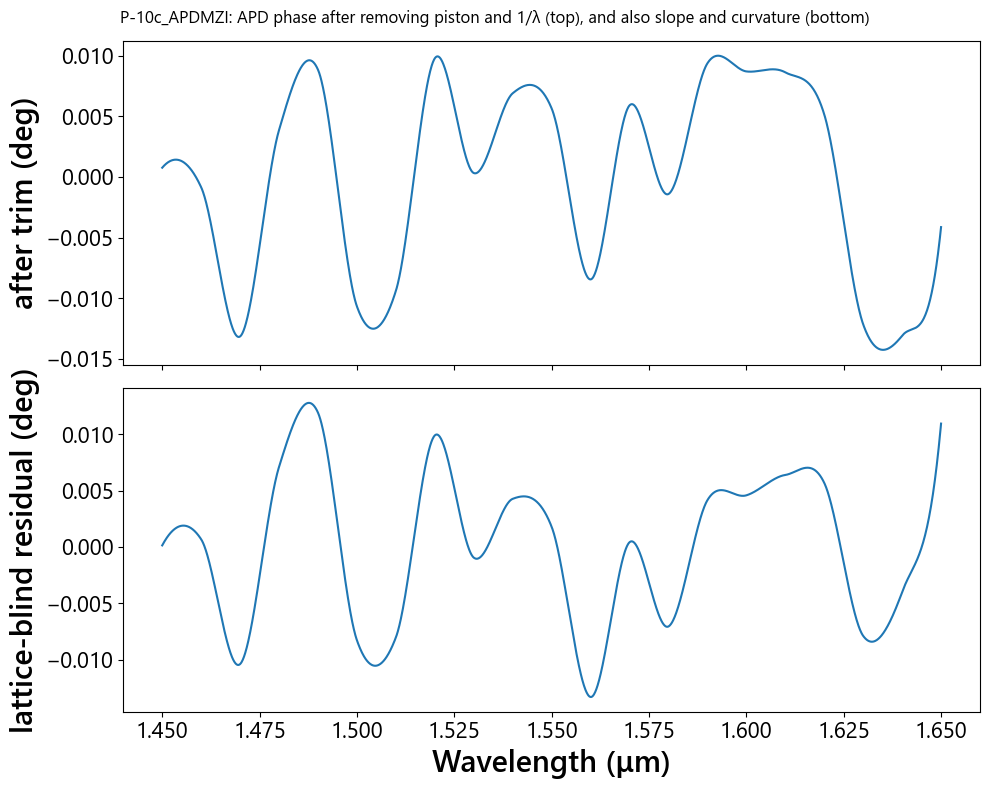

In [16]:
# Fit and subtract the terms the system can remove, in degrees
y = np.degrees(dphi_apd)
u = (wl - wl.mean()) / (wl.max() - wl.min())                 # scaled wavelength, keeps the fit well conditioned
terms = {"piston": np.ones_like(wl), "slope": u, "curvature": u ** 2, "heater 1/λ": wl.mean() / wl}

def residual(names):
    A = np.column_stack([terms[n] for n in names])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    return y - A @ coef

r_trim = residual(["piston", "heater 1/λ"])                                   # what the trim heater leaves
r_lattice = residual(["piston", "slope", "curvature", "heater 1/λ"])           # what the lattice leaves (lattice-blind)

print(f"{design_name}: after trim, worst {np.abs(r_trim).max():.4f} deg (rms {np.sqrt(np.mean(r_trim ** 2)):.4f}); "
      f"lattice-blind residual, worst {np.abs(r_lattice).max():.4f} deg (rms {np.sqrt(np.mean(r_lattice ** 2)):.4f})")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax1.plot(wl, r_trim)
ax1.set_ylabel("after trim (deg)")
ax2.plot(wl, r_lattice)
ax2.set_ylabel("lattice-blind residual (deg)")
ax2.set_xlabel("Wavelength (μm)")
fig.suptitle(f"{design_name}: APD phase after removing piston and 1/λ (top), and also slope and curvature (bottom)")
plt.tight_layout()
plt.show()